# Fruit Ripeness Classification — Mini Project 2

## 1. Project introduction and objectives

This notebook compares six image classifiers for **Unripe, Semi-ripe, Ripe, and Overripe** bananas, mangoes, and apples. It uses the attached Mini Project 1 archive and the original images under `dataset/raw/<class>/` as independent samples. The archive also contains preprocessed images; these are derived copies and are deliberately excluded.

The four traditional experiments use SIFT Bag of Visual Words and Harris corner/color features with SVM and cosine-prototype classifiers. The deep experiments use an ImageNet-pretrained ResNet50 and a genuine pretrained MViT. All six use one reproducible stratified 80:20 split. Metrics are computed only from predictions on its held-out test portion; reported values are produced at runtime.

## 2. Imports and dependency installation

This cell installs the image-processing and ML packages. Colab usually includes PyTorch and torchvision already; the fallback installs them only if missing, preserving the runtime's GPU-enabled build when present.

In [3]:
%pip install -q opencv-contrib-python-headless scikit-learn pandas matplotlib tqdm timm
import importlib.util, subprocess, sys
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "torchvision"])

In [4]:
import sys, os, zipfile, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
import torch
import cv2
print("Python", sys.version.split()[0], "| OpenCV", cv2.__version__, "| PyTorch", torch.__version__)
# The implementation file must be alongside this notebook in Colab/current folder.
PROJECT_DIR = Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))
from PES1UG24CS379_PES1UG24CS391_PES1UG24CS380 import (CLASSES, extract_dataset, load_samples, show_samples, make_split,
                            sift_descriptors, fit_bovw, bovw_transform, harris_features,
                            cosine_prototype_predict, evaluate, classic_experiments,
                            run_resnet, run_mvit, plot_results, seed_everything)
seed_everything(42)

Python 3.13.16 | OpenCV 5.0.0 | PyTorch 2.14.1+cu130


## 3. GPU and environment verification

ResNet and MViT use CUDA when available and otherwise run on CPU. The notebook prints the actual device and GPU name. Batch sizes default to 32 for ResNet and 16 for MViT, conservative choices for a Colab Tesla T4.

In [5]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No CUDA GPU available")
print("SIFT available:", hasattr(cv2, "SIFT_create"))
if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError("SIFT is unavailable. Install opencv-contrib-python-headless, restart the runtime, and rerun.")

Selected device: cuda
GPU: Tesla T4
SIFT available: True


## 4. Dataset extraction and inspection

Upload `ip_miniproject.zip` to the Colab session (or set `ZIP_PATH` to its location). Extraction prints the observed archive tree. The loader then locates the folder containing all four raw class directories; it does not assume a fixed extra wrapper directory. No derived/preprocessed directory is used.

In [6]:
ZIP_PATH = Path("ip_miniproject.zip")
if not ZIP_PATH.exists():
    try:
        from google.colab import files
        print("Upload the Mini Project 1 ZIP archive")
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith(".zip")]
        if not candidates: raise FileNotFoundError("No ZIP archive was uploaded")
        ZIP_PATH = Path(candidates[0])
    except ImportError as exc:
        raise FileNotFoundError("Place ip_miniproject.zip in the working directory or update ZIP_PATH") from exc
RAW_ROOT = extract_dataset(ZIP_PATH, Path("work") / "dataset_extracted")
print("Raw image root:", RAW_ROOT)

Extracted ip_miniproject.zip to /content/work/dataset_extracted
Dataset tree (to depth 4): work/dataset_extracted
dataset_extracted/ (3 files)
  dataset/ (1 files)
    preprocessed/ (0 files)
      clahe/ (0 files)
        overripe/ (85 files)
        ripe/ (55 files)
        semiripe/ (61 files)
        unripe/ (60 files)
      fourier_lpf/ (0 files)
        overripe/ (85 files)
        ripe/ (55 files)
        semiripe/ (61 files)
        unripe/ (60 files)
      laplacian/ (0 files)
        overripe/ (85 files)
        ripe/ (55 files)
        semiripe/ (61 files)
        unripe/ (60 files)
      median/ (0 files)
        overripe/ (85 files)
        ripe/ (55 files)
        semiripe/ (61 files)
        unripe/ (60 files)
      resize/ (0 files)
        overripe/ (85 files)
        ripe/ (55 files)
        semiripe/ (61 files)
        unripe/ (60 files)
    raw/ (1 files)
      Overripe/ (85 files)
      Ripe/ (55 files)
      Semi-ripe/ (61 files)
      Unripe/ (60 files)
  example

## 5. Dataset loading and visualization

Each accepted image is decoded before use. Corrupted/unreadable files are reported and skipped. Samples come exclusively from the raw class folders. The PDF documentation describes banana, mango, and apple images and the four ripeness stages; it is contextual documentation, not a source of experimental labels or metrics.

Loaded 261 readable original images; counts: Counter({'Overripe': 85, 'Semi-ripe': 61, 'Unripe': 60, 'Ripe': 55})
Fruit varieties found in filenames: ['apple', 'banana', 'mango']


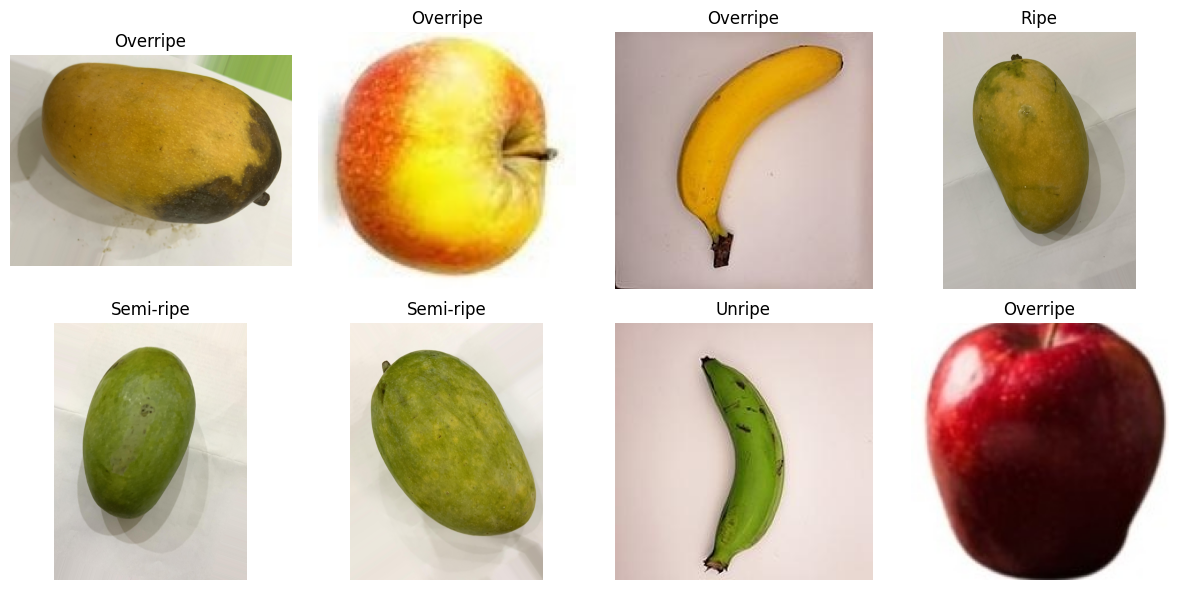

Total independent readable raw images: 261


In [7]:
samples = load_samples(RAW_ROOT)
show_samples(samples, n=8)
print("Total independent readable raw images:", len(samples))

## 6. Train/test split

A single stratified split is made from original image paths with seed 42. Because all derived versions are excluded before splitting, an original cannot be separated from a preprocessed copy. This exact `train_samples` / `test_samples` pair is passed to every experiment. Any learned vocabulary, scaler, classifier, or head is fit using training images only.

In [8]:
train_samples, test_samples = make_split(samples, test_size=0.20, seed=42)
train_paths = {str(s["path"].resolve()) for s in train_samples}
test_paths = {str(s["path"].resolve()) for s in test_samples}
assert train_paths.isdisjoint(test_paths)
print(f"Verified disjoint raw paths: {len(train_paths)} train, {len(test_paths)} test")

Train counts: Counter({'Overripe': 68, 'Unripe': 48, 'Semi-ripe': 48, 'Ripe': 44})
Test counts:  Counter({'Overripe': 17, 'Semi-ripe': 13, 'Unripe': 12, 'Ripe': 11})
Split: 208 train / 53 test, seed=42; originals only
Verified disjoint raw paths: 208 train, 53 test


## 7. SIFT feature extraction

SIFT converts each image to grayscale and detects local keypoints. A keypoint descriptor is a 128-value vector; images produce different descriptor counts. We fit a 64-word MiniBatch KMeans visual vocabulary using descriptors from **training images only**. Each image is then represented by a fixed-length, L2-normalized histogram of visual-word assignments. An image with no keypoints receives a zero histogram.

In [9]:
print("SIFT will be extracted once and reused by experiments 1 and 2.")
train_sift = sift_descriptors(tqdm(train_samples, desc="SIFT train"))
test_sift = sift_descriptors(tqdm(test_samples, desc="SIFT test"))
print("Images with SIFT descriptors — train:", sum(len(d)>0 for d in train_sift), "/", len(train_sift),
      "test:", sum(len(d)>0 for d in test_sift), "/", len(test_sift))
y_train = np.array([s["label"] for s in train_samples])
y_test = np.array([s["label"] for s in test_samples])
sift_vocabulary = fit_bovw(train_sift, vocab_size=64, seed=42)
X_sift_train = bovw_transform(train_sift, sift_vocabulary)
X_sift_test = bovw_transform(test_sift, sift_vocabulary)
print("Train/test BoVW shapes:", X_sift_train.shape, X_sift_test.shape)

SIFT will be extracted once and reused by experiments 1 and 2.


SIFT train:   0%|          | 0/208 [00:00<?, ?it/s]

SIFT test:   0%|          | 0/53 [00:00<?, ?it/s]

Images with SIFT descriptors — train: 208 / 208 test: 53 / 53
Train/test BoVW shapes: (208, 64) (53, 64)


## 8. SIFT + SVM

An RBF Support Vector Machine learns class boundaries over the fixed-length BoVW histograms. The standardization and SVM are fitted only on training histograms. Accuracy and macro-averaged precision, recall, F1, and a four-class confusion matrix are computed from held-out predictions.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
results = []
sift_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=42))
sift_svm.fit(X_sift_train, y_train)
pred_sift_svm = sift_svm.predict(X_sift_test)
results.append(evaluate("SIFT + SVM", y_test, pred_sift_svm))
print(results[-1])

{'Experiment': 'SIFT + SVM', 'Accuracy': 0.6981132075471698, 'Macro Precision': 0.6884615384615385, 'Macro Recall': 0.6854860825449061, 'Macro F1': 0.6850961538461539, 'Confusion Matrix': array([[ 8,  3,  1,  0],
       [ 2,  8,  3,  0],
       [ 1,  2,  7,  1],
       [ 1,  0,  2, 14]])}


## 9. SIFT + Cosine Similarity

For each class, the training BoVW vectors are averaged to create a class prototype. Each test vector is assigned to the prototype with the largest cosine similarity. This is a documented prototype classifier, not a second learned model; its prototypes use training vectors only.

In [11]:
pred_sift_cosine = cosine_prototype_predict(X_sift_train, y_train, X_sift_test)
results.append(evaluate("SIFT + Cosine Similarity", y_test, pred_sift_cosine))
print(results[-1])

{'Experiment': 'SIFT + Cosine Similarity', 'Accuracy': 0.4716981132075472, 'Macro Precision': 0.4831439393939394, 'Macro Recall': 0.47676710544357603, 'Macro F1': 0.4669312169312169, 'Confusion Matrix': array([[7, 3, 2, 0],
       [3, 4, 6, 0],
       [1, 1, 6, 3],
       [4, 3, 2, 8]])}


## 10. Harris feature extraction

Harris corner detection responds to local intensity changes in two directions. Each fixed-size grayscale image contributes normalized corner counts in a 4×4 spatial grid, global response/count statistics, and an HSV color histogram. Combining spatial corner structure with color gives a fixed-length feature vector suitable for both classifiers. These are deterministic image features; learned normalization is still fit only on training data.

In [12]:
X_harris_train = harris_features(tqdm(train_samples, desc="Harris train"))
X_harris_test = harris_features(tqdm(test_samples, desc="Harris test"))
print("Train/test Harris feature shapes:", X_harris_train.shape, X_harris_test.shape)

Harris train:   0%|          | 0/208 [00:00<?, ?it/s]

Harris test:   0%|          | 0/53 [00:00<?, ?it/s]

Train/test Harris feature shapes: (208, 53) (53, 53)


## 11. Harris + SVM

An RBF SVM classifies the Harris feature vectors. `StandardScaler` learns feature means and scales from the training set through a pipeline, then applies them to the test set. All reported metrics use the held-out test predictions.

In [13]:
harris_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=42))
harris_svm.fit(X_harris_train, y_train)
pred_harris_svm = harris_svm.predict(X_harris_test)
results.append(evaluate("Harris + SVM", y_test, pred_harris_svm))
print(results[-1])

{'Experiment': 'Harris + SVM', 'Accuracy': 0.7358490566037735, 'Macro Precision': 0.7574505173189383, 'Macro Recall': 0.7383878376525436, 'Macro F1': 0.7341938405797102, 'Confusion Matrix': array([[ 7,  4,  0,  1],
       [ 2, 11,  0,  0],
       [ 0,  2,  9,  0],
       [ 0,  2,  3, 12]])}


## 12. Harris + Cosine Similarity

The training feature vectors are standardized using training-set statistics only. We then average those standardized vectors within each class and assign each test vector to the class prototype with maximum cosine similarity.

In [14]:
harris_scaler = StandardScaler().fit(X_harris_train)
H_train_scaled = harris_scaler.transform(X_harris_train)
H_test_scaled = harris_scaler.transform(X_harris_test)
pred_harris_cosine = cosine_prototype_predict(H_train_scaled, y_train, H_test_scaled)
results.append(evaluate("Harris + Cosine Similarity", y_test, pred_harris_cosine))
print(results[-1])

{'Experiment': 'Harris + Cosine Similarity', 'Accuracy': 0.5471698113207547, 'Macro Precision': 0.5596681096681098, 'Macro Recall': 0.5485911147675854, 'Macro F1': 0.5384594497497723, 'Confusion Matrix': array([[ 6,  3,  1,  2],
       [ 3, 10,  0,  0],
       [ 3,  3,  5,  0],
       [ 2,  2,  5,  8]])}


## 13. ResNet feature extraction and classification

ResNet50 is loaded with pretrained ImageNet weights. Its pretrained backbone is frozen; the original final layer is removed and only a newly initialized four-output linear head is trained. CrossEntropyLoss receives raw logits (no Softmax is applied before the loss); Softmax can be applied to logits to interpret class probabilities. Evaluation selects the largest logit, equivalent to the largest Softmax probability. The same split is used. If weights cannot be loaded, execution stops with an actionable error rather than silently changing models.

In [15]:
resnet_result, resnet_backbone, resnet_head = run_resnet(
    train_samples, test_samples, device=DEVICE, epochs=8, batch_size=32)
results.append(resnet_result)
print(resnet_result)
assert resnet_head.out_features == 4
assert all(not p.requires_grad for p in resnet_backbone.parameters())
assert all(p.requires_grad for p in resnet_head.parameters())
print("Verified: ResNet backbone frozen; only four-class head trainable.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 156MB/s]


ResNet50 (frozen backbone) epoch 1/8: train loss=1.3404
ResNet50 (frozen backbone) epoch 2/8: train loss=1.2049
ResNet50 (frozen backbone) epoch 3/8: train loss=1.0978
ResNet50 (frozen backbone) epoch 4/8: train loss=1.0059
ResNet50 (frozen backbone) epoch 5/8: train loss=0.9257
ResNet50 (frozen backbone) epoch 6/8: train loss=0.8600
ResNet50 (frozen backbone) epoch 7/8: train loss=0.7966
ResNet50 (frozen backbone) epoch 8/8: train loss=0.7443
{'Experiment': 'ResNet50 (frozen backbone)', 'Accuracy': 0.9056603773584906, 'Macro Precision': 0.9272875816993464, 'Macro Recall': 0.8901515151515151, 'Macro F1': 0.8973228525860105, 'Confusion Matrix': array([[10,  2,  0,  0],
       [ 0, 13,  0,  0],
       [ 0,  2,  8,  1],
       [ 0,  0,  0, 17]])}
Verified: ResNet backbone frozen; only four-class head trainable.


## 14. MViT feature extraction and classification

This experiment requests `mvitv2_small.fb_in1k`, a Multiscale Vision Transformer model through `timm`. The pretrained backbone is used as a feature extractor and frozen; only a new linear layer with four outputs is trained. CrossEntropyLoss consumes logits, and Softmax interprets class probabilities. The architecture is explicitly named and the implementation refuses to substitute another architecture. If this exact model or its pretrained weights are unavailable in the installed `timm` version/network cache, the cell raises a clear error. On a Tesla T4, batch size 16 is selected to manage memory.

In [16]:
mvit_result, mvit_backbone, mvit_head = run_mvit(
    train_samples, test_samples, device=DEVICE, epochs=8, batch_size=16,
    model_name="mvitv2_small.fb_in1k")
results.append(mvit_result)
print(mvit_result)
assert mvit_head.out_features == 4
assert all(not p.requires_grad for p in mvit_backbone.parameters())
assert all(p.requires_grad for p in mvit_head.parameters())
print("Verified: MViT backbone frozen; only four-class head trainable.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  140MB            

model.safetensors: downloading bytes:           |  0.00B            

MViT (mvitv2_small.fb_in1k) epoch 1/8: train loss=1.3106
MViT (mvitv2_small.fb_in1k) epoch 2/8: train loss=1.1274
MViT (mvitv2_small.fb_in1k) epoch 3/8: train loss=1.0123
MViT (mvitv2_small.fb_in1k) epoch 4/8: train loss=0.9155
MViT (mvitv2_small.fb_in1k) epoch 5/8: train loss=0.8492
MViT (mvitv2_small.fb_in1k) epoch 6/8: train loss=0.7924
MViT (mvitv2_small.fb_in1k) epoch 7/8: train loss=0.7493
MViT (mvitv2_small.fb_in1k) epoch 8/8: train loss=0.7069
{'Experiment': 'MViT (mvitv2_small.fb_in1k)', 'Accuracy': 0.7547169811320755, 'Macro Precision': 0.7739130434782608, 'Macro Recall': 0.7217451665981078, 'Macro F1': 0.7114420062695925, 'Confusion Matrix': array([[ 9,  3,  0,  0],
       [ 1, 12,  0,  0],
       [ 0,  1,  3,  7],
       [ 0,  0,  1, 16]])}
Verified: MViT backbone frozen; only four-class head trainable.


## 15. Performance comparison

This section displays one comparison table and accuracy chart for all six experiments, plus one confusion matrix plot per experiment. These values are generated only after the models have predicted the same held-out test set.

,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SIFT + SVM,0.698113,0.688462,0.685486,0.685096
1,SIFT + Cosine Similarity,0.471698,0.483144,0.476767,0.466931
2,Harris + SVM,0.735849,0.757451,0.738388,0.734194
3,Harris + Cosine Similarity,0.547170,0.559668,0.548591,0.538459
4,ResNet50 (frozen backbone),0.905660,0.927288,0.890152,0.897323
5,MViT (mvitv2_small.fb_in1k),0.754717,0.773913,0.721745,0.711442


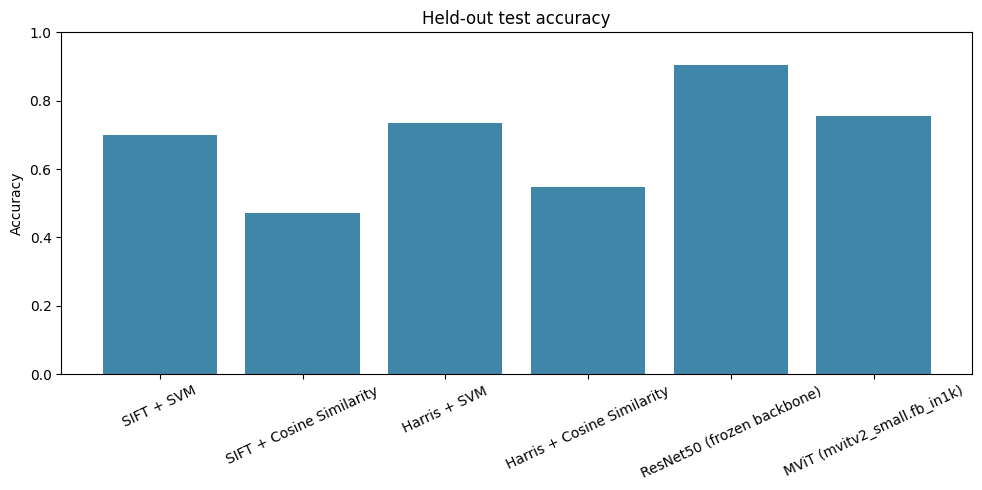

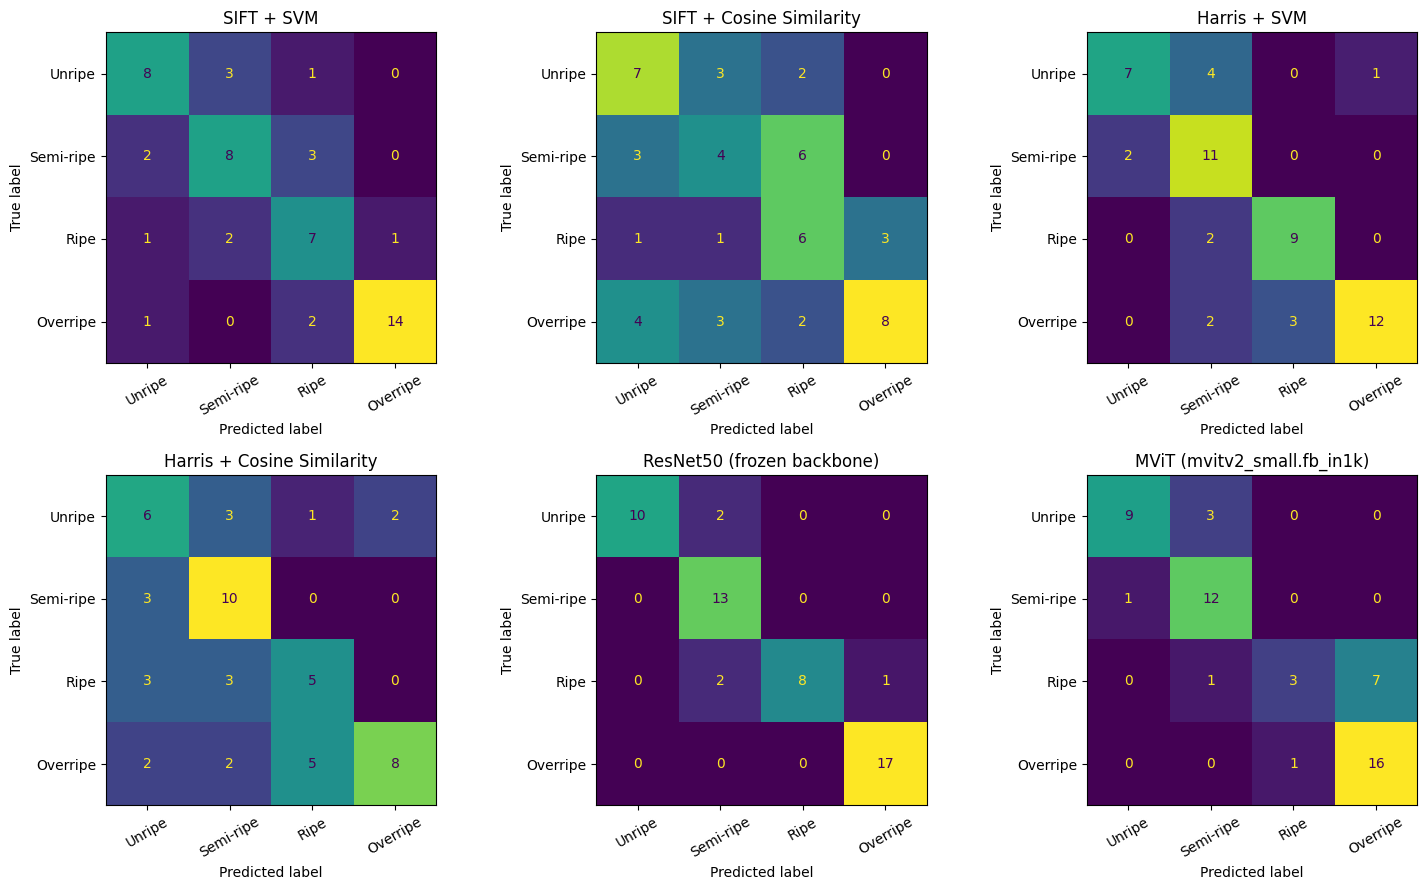

,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SIFT + SVM,0.698113,0.688462,0.685486,0.685096
1,SIFT + Cosine Similarity,0.471698,0.483144,0.476767,0.466931
2,Harris + SVM,0.735849,0.757451,0.738388,0.734194
3,Harris + Cosine Similarity,0.547170,0.559668,0.548591,0.538459
4,ResNet50 (frozen backbone),0.905660,0.927288,0.890152,0.897323
5,MViT (mvitv2_small.fb_in1k),0.754717,0.773913,0.721745,0.711442


In [17]:
assert len(results) == 6, f"Expected six completed experiments, found {len(results)}"
comparison_table = plot_results(results)
display(comparison_table)

## 16. Results interpretation and conclusion

The highest held-out accuracy is identified below from actual results. Macro-F1 gives equal weight to each ripeness class and is useful when class counts differ. Inspect each confusion matrix to see which adjacent ripeness stages are most often confused. Traditional features and pretrained deep models capture different cues, so a single small dataset split should be interpreted cautiously. No metric is prefilled or fabricated.

In [18]:
best = comparison_table.sort_values(["Accuracy", "Macro F1"], ascending=False).iloc[0]
print(f"Best observed test accuracy: {best['Experiment']} — {best['Accuracy']:.3f}")
print("Interpretation is based on this run's held-out metrics; rerun from the top for a fresh, reproducible run.")

Best observed test accuracy: ResNet50 (frozen backbone) — 0.906
Interpretation is based on this run's held-out metrics; rerun from the top for a fresh, reproducible run.
